O fabrică produce componente electronice, dintre care unele pot fi defecte. Notăm cu $\theta$ probabilitatea
ca o componentă aleasă aleatoriu să fie defectă. Presupunem că rezultatele testelor sunt independente
condiţionat de $\theta$.
Din experienţa anterioară, alegem distribuţia a priori $\theta ∼ Beta(2, 18)$. Dintre $n = 50$ de componente testate,
$y = 8$ sunt defecte.

a) Modelul probabilistic. Scrieţi distribuţia lui $Y | \theta$, unde $Y$ este numărul de componente defecte din
cele 50 testate, şi funcţia de verosimilitate $P (Y = y | \theta)$.

b) Actualizarea Bayesiană. Folosind formula lui Bayes, determinaţi distribuţia a posteriori a lui $\theta$.
Justificaţi matematic rezultatul, folosind conjugarea Beta–Binomial.

c) Estimarea parametrului. Calculaţi estimatorul de maximă verosimilitate (MLE), estimatorul MAP şi
media a posteriori. Comparaţi valorile şi explicaţi diferenţele.

d) Vizualizare. Reprezentaţi pe acelaşi grafic densităţile a priori şi a posteriori. Explicaţi cum au modificat
datele informaţia despre rata de defectare.

e) Incertitudine. Determinaţi numeric un interval credibil central de $95\%$ pentru $\theta$, folosind scipy.stats.beta.
Interpretaţi rezultatul.

f) Decizie practică. Fabrica doreşte ca rata de defectare să fie sub $10\%$. Calculaţi probabilitatea a posteriori
$P(\theta < 0.10 | Y = 8)$ şi discutaţi în ce măsură datele susţin această cerinţă.

g) Predicţie Bayesiană. Se testează încă $10$ componente produse în aceleaşi condiţii. Calculaţi probabili-
tatea predictivă ca niciuna să nu fie defectă. 

Indiciu: dacă $X$ este numărul de componente defecte din noul eşantion, folosiţi

$$P(X=0|Y=8)=\int_{0}^1 (1-\theta)^{10}p(\theta | Y=8)d\theta$$

a) Modelul probabilistic. Scrieţi distribuţia lui $Y | \theta$, unde $Y$ este numărul de componente defecte din
cele 50 testate, şi funcţia de verosimilitate $P (Y = y | \theta)$.

$$P(Y = y | \theta)=\binom{N}{y} \cdot \theta^y \cdot (1-\theta)^{N-y} \propto Beta(\theta,y+1,50-y+1)$$

deci $$P(Y = 8 | \theta)=Beta(\theta,9,43)$$

b) Actualizarea Bayesiană. Folosind formula lui Bayes, determinaţi distribuţia a posteriori a lui $\theta$.
Justificaţi matematic rezultatul, folosind conjugarea Beta–Binomial.

$$P(\theta | Y=y) \stackrel{F. Bayes}{=} \frac{P(Y = y | \theta) \cdot P(\theta)}{P(Y=y)} \propto \theta^y \cdot (1-\theta)^{N-y} \cdot Beta(\theta, 2,18) \propto \theta^{y+2-1} \cdot (1-\theta)^{50-y+18-1} \propto Beta(\theta,y+2,68-y)$$

c) $$\theta_{MLE}=\argmax_{\theta \in [0,1]}{P(Y=8|\theta)}\stackrel{\text{eliminand coef binomial}}{=}\argmax_{\theta \in [0,1]} \theta^8 \cdot (1-\theta)^{42}\stackrel{\ln \nearrow}{=}\argmax_{\theta \in (0,1)} 8 \cdot \ln(\theta) + 42 \cdot \ln(1-\theta)$$

Deoarece $\theta^8 \cdot (1-\theta)^{42} \ge 0$, cu egalitate pentru $\theta \in \{0,1\}$, putem presupune că $\argmax_{\theta \in [0,1]} \theta^8 \cdot (1-\theta)^{42} \not \in \{0,1\}$

Pentru $a,b \in \mathbb{N}$, $a^2+b^2 > 0$, fie $f_{ab}(\theta)=a \cdot \ln(\theta) + b \cdot \ln (1-\theta)$. Atunci:

- $f^{'}_{ab}(\theta)=\frac{a}{\theta} - \frac{b}{1-\theta}$
- $f^{''}_{ab}(\theta)=-\frac{a}{\theta^2} - \frac{b}{(1-\theta)^2} \le 0$, deci $f_{ab}$ este concavă.

$f_{ab}(\theta)$ este un maxim/minim local dacă $f^{'}_{ab}(\theta)=\frac{a}{\theta} - \frac{b}{1-\theta}=0 \Leftrightarrow \theta = \frac{a}{a+b}$

În plus, deoarece funcția $f_{ab}$ este concavă, reiese că maximul global este atins la $\theta=\frac{a}{a+b} \Leftrightarrow \argmax_{\theta \in [0,1]} f_{ab}(\theta)=\frac{a}{a+b}$

Aplicând relația de mai sus, obținem că $\argmax_{\theta \in (0,1)} 8 \cdot \ln(\theta) + 42 \cdot \ln(1-\theta)=\frac{8}{8+42}=\frac{8}{50}$

$$\theta_{MAP}=\argmax_{\theta \in [0,1]}P(Y=8|\theta) \cdot P(\theta)\stackrel{calc.}{=}\argmax_{\theta \in (0,1)} (8+2-1){\cdot \ln(\theta) + (42+18-1) \cdot \ln(1-\theta)}=\frac{9}{9+59}=\frac{9}{68}$$

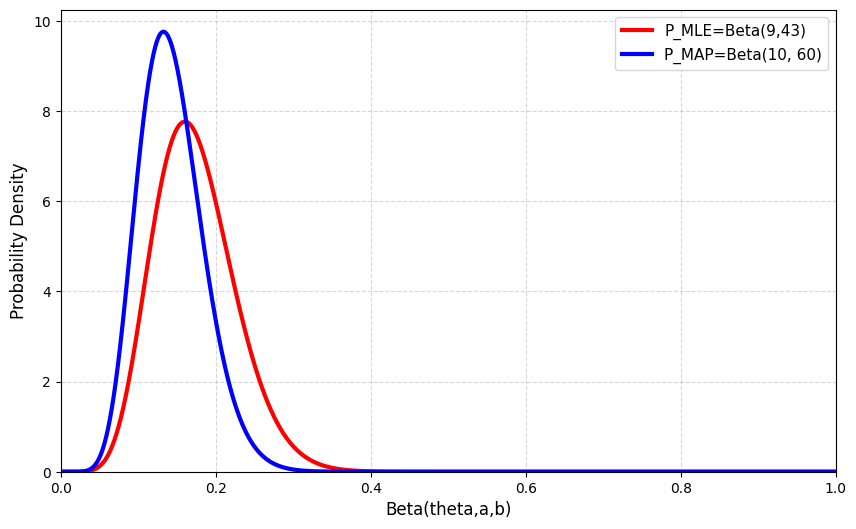

confidence interval for Beta(9, 43): 0.08400869980316125 0.2858762867315592
confidence interval for Beta(10, 60): 0.07174913989206377 0.2332189597948612
P(theta < 0.1 | Y=8)=0.14837323361352775
0.23602209274441907


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta, bootstrap
x = np.linspace(0, 1, 2000)

shapes = [
    {"a": 9, "b": 43, "color": "red", "label": "P_MLE=Beta(9,43)"},
    {"a": 10, "b": 60, "color": "blue", "label": "P_MAP=Beta(10, 60)"},
]

plt.figure(figsize=(10, 6))
ys = []
for shape in shapes:
    a, b = shape["a"], shape["b"]
    y = beta.pdf(x, a, b)
    ys.append(y)
    plt.plot(x, y, linewidth=3, color=shape["color"], label=shape["label"])

plt.xlabel("Beta(theta,a,b)", fontsize=12)
plt.ylabel("Probability Density", fontsize=12)
plt.xlim(0, 1)
plt.ylim(bottom=0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11, frameon=True)
plt.show()

for shape in shapes:
    confidence = 0.95
    a, b = shape["a"], shape["b"]
    low, high = beta.ppf([0.5 - confidence/2, 0.5 + confidence/2], a, b)
    print(f"confidence interval for Beta({a}, {b}):", low, high)

print(f"P(theta < 0.1 | Y=8)={beta.cdf(0.1, 10, 60)}")

def g(splits):
    s = 0
    for i in range(splits):
        theta = (i+0.5)/splits
        s += ((1-theta)**10) * beta.pdf(theta, 10, 60)
    return s/splits

print(g(100000))

e) Intervalele de mai sus conțin $\frac{8}{50}$, respectiv $\frac{9}{68}$.

Diferențele apar deoarece estimatorul MAP mai "adaugă" $2-1=1$ componentă defectă fictivă și $18-1=17$ componente nedefecte fictive. 

f) $P(theta < 0.1 | Y=8) = \int_{0}^{0.1} Beta(\theta, 10, 60) \cdot d\theta \approx 14.8\%$

Această estimare are sens, deoarece $\theta_{MAP}=\frac{9}{68} \approx 13.2\% > \frac{1}{10}$ și PPF-ul funcției Beta este cel mai mare în jurul lui $\theta_{MAP}=\frac{9}{68}$, ca în graficul de mai sus. În plus, $P(\theta < 0.717 | Y=8) < 2.5\%$.

g) Integrala se evaluează la $0.23\ldots$ (vezi functia g). 
